# View RAPID alerts

How to open and look at alerts produced by the `alerts` package, built up in steps:

1. **If you need an example alert**: make the files from the database (or skip this if you have some).
2. **Read one alert** and look at what is in it (two lines of `fastavro`).
3. **Plot one stamp** from its FITS bytes.
4. **A closer look at one alert**: key fields, the three stamps, and the light curve.
5. **Whole chips**: read a container file with every alert from one difference image (one exposure + SCA), tabulate and summarize it.

Two file formats appear throughout:

- **schemaless** (`alert_<sid>.avro`): one alert, the raw bytes as sent over Kafka. Needs the package schema to decode.
- **container** (`chip_<pid>.avro`): many alerts in Avro object-container format with the schema in the file header, so it is self-describing.

Fluxes are instrumental everywhere (`sources.fluxfit`, the PSF-fit flux in the difference image's own units); the nJy calibration the schema promises is not applied yet.


In [1]:
import sys
import io
import fastavro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.visualization import ZScaleInterval, simple_norm
from astropy.io import fits

# Insert alerts and rapid paths
sys.path.insert(0, "../alerts") # where your alerts directory is
sys.path.insert(0, "..") # where your rapid directory is

import alerts
from alerts.produce import load_schema

## If you need an example alert

The files used below (`alert_5695908013.avro`, `chip_344197.avro`) were produced with the next cell. It is kept commented out so a fresh kernel never tries to reach the database by accident; uncomment to regenerate them or to make files for a different source or chip. Needs the DB and AWS credentials in `rapid_setup.env` (gitignored, at the repo root) and network access to the DB server. The chip run takes a while because of the forced-photometry look-back.

- `load_dotenv` sets the five DB variables `RAPIDDB` insists on (DBSERVER, DBNAME, DBPORT, DBUSER, DBPASS) plus the AWS keys for fetching cutouts from S3.
- `make_provider` takes the same options as the `alerts.cli` flags. `provider1` skips forced photometry so the single alert takes seconds; `provider2` raises the per-chip cap from the default 2000 to 3000 highest-S/N detections (the cap is a temporary stand-in for a real/bogus cut; `max_sources=0` disables it).
- The single alert is written as the raw bytes `produce_alert` returns (schemaless, as sent over Kafka). The chip goes through `open_alert_archive`, which writes a self-describing container file. To get a container file for a single alert instead, pass `archive=` to `produce_alert` inside the same `with` block.

The same thing from the command line: `python -m alerts.cli 5695908013` for one alert, `python -m alerts.cli --pid 344197 --save chip_344197.avro` for a chip.


In [2]:
# # Make example alert files (see the notes above; uncomment to run)
# from alerts.cli import make_provider
# from alerts.produce import batch_produce, open_alert_archive, produce_alert
# from dotenv import load_dotenv

# # DB + AWS credentials. Relative to this notebook's directory (notebooks/).
# load_dotenv("../rapid_setup.env", override=True)

# batch_filename = "chip_344197.avro"
# provider1 = make_provider(forced_phot=False)   # quick: no forced-phot look-back
# provider2 = make_provider(max_sources=3000)    # whole chip, cap raised from 2000

# # Single alert: schemaless bytes, exactly what would go to Kafka.
# alert_bytes = produce_alert(provider1, 5695908013)
# with open("alert_5695908013.avro", "wb") as f:
#     f.write(alert_bytes)

# # Batch chip: every surviving source on diffimages.pid 344197 (expId 80896, SCA 7),
# # appended to one container file. The provider cleans up staged S3 products on exit.
# with provider2, open_alert_archive(batch_filename) as archive:
#     count = batch_produce(provider2, 344197, archive=archive)
# print(count)

## If you have an alert, start here

A single alert file holds the raw Avro bytes of one alert, with no schema inside. Decoding it takes the schema that it was produced with (`load_schema()` gives the current one; `load_schema(version="00.06")` an older one) and one `fastavro` call. The result is a plain dict.

The top level holds the triggering `diaSource`, the `diaObject` summary, history arrays (`prvDiaSources`, `prvDiaForcedSources`), cross-match arrays (`refStarMatches`, `nedMatches`, `gaiaMatches`, ...) and three stamps as FITS bytes.


In [3]:
# The files everything below reads. Point these at your own alerts if you have them.
alert_filename = "alert_5695908013.avro"   # one alert, schemaless
chip_filename = "chip_344197.avro"         # one chip, Avro container

In [4]:
# Loading schema and reading the alert
schema = load_schema()
with open(alert_filename, "rb") as f:
    alert = fastavro.schemaless_reader(f, schema)

# What is in it: top-level keys
list(alert.keys())


['schemaVersion',
 'pipelineVersion',
 'diaSourceId',
 'diaSource',
 'prvDiaSources',
 'diaObject',
 'prvDiaForcedSources',
 'ssMatches',
 'refStarMatches',
 'refGalaxyMatches',
 'nedMatches',
 'lvsMatches',
 'gaiaMatches',
 'cutoutDifference',
 'cutoutScience',
 'cutoutReference',
 'observation_reason',
 'target_name']

In [5]:
# A few fields of the triggering source, and how much history came with it
src = alert["diaSource"]
print(f"Source ID: {src['diaSourceId']}")
print(f"Position: ra {src['ra']:.6f}, dec {src['dec']:.6f}  (band {src['band']})")
print(f"PSF flux: {src['psfFlux']:.4g} (instrumental), S/N: {src['snr']:.1f}")
print(f"History: {len(alert['prvDiaSources'] or [])} previous detections, "
      f"{len(alert['prvDiaForcedSources'] or [])} forced-photometry points")

Source ID: 5695908013
Position: ra 268.343664, dec -28.267838  (band W146)
PSF flux: 202.1 (instrumental), S/N: 13.9
History: 33 previous detections, 0 forced-photometry points


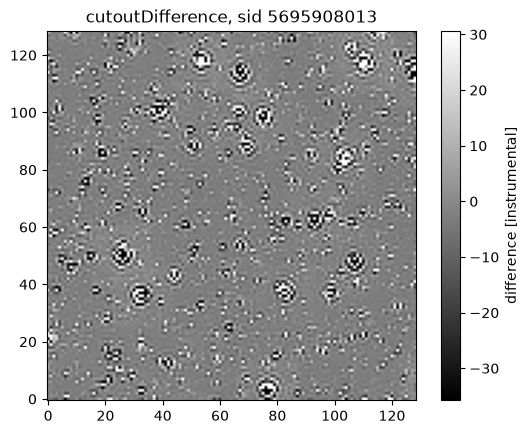

In [6]:
# The stamps are FITS files held as bytes: one 129x129 image in the primary HDU.
# Wrap the bytes in BytesIO so astropy can open them like a file.
hdul = fits.open(io.BytesIO(alert["cutoutDifference"]))
data = hdul[0].data

vmin, vmax = ZScaleInterval().get_limits(data)      # DS9-style zscale stretch
plt.imshow(data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
plt.colorbar(label="difference [instrumental]")
plt.title(f"cutoutDifference, sid {alert['diaSourceId']}")
plt.show()

# The other two are alert["cutoutScience"] and alert["cutoutReference"]; any may be None.

## A closer look at one alert

The same ingredients, wrapped up: `show_alert` prints the triggering source's key fields and object history, lists the cross-match arrays that are non-empty, draws the science, reference and difference stamps side by side, and plots the light curve from `prvDiaSources` (earlier detections of the same object) and `prvDiaForcedSources` (forced photometry at the object position) with this alert marked.

It takes an alert dict, so it works on the one just read or on any record pulled out of a chip file later. Any of the three stamps may be null.


In [7]:
def show_alert(alert, stamp_fields=("cutoutScience", "cutoutReference", "cutoutDifference")):
    """One alert: key fields, the three stamps, and the detection/forced-phot light curve.

    Returns the prvDiaSources and prvDiaForcedSources as DataFrames for further poking."""
    src = alert["diaSource"]
    obj = alert.get("diaObject") or {}
    print(f"sid {src['diaSourceId']}  expId {src['expId']} sca {src['detector']} pid {src['pid']}  "
          f"band {src['band']}  mjd {src['midpointMjd']:.5f}")
    print(f"ra {src['ra']:.6f} dec {src['dec']:.6f}  psfFlux {src['psfFlux']:.4g} +/- {src['psfFluxErr']:.3g}  "
          f"snr {src['snr']:.1f}  {'negative' if src['isNegative'] else 'positive'}")
    print(f"reliability {src.get('reliability')} (threshold {src.get('reliabilityThreshold')}, "
          f"model {src.get('reliabilityVersion')})")
    if obj:
        print(f"diaObject {obj.get('diaObjectId')}: {obj.get('nDiaSources')} detections, "
              f"mjd {obj.get('firstDiaSourceMjd')} .. {obj.get('lastDiaSourceMjd')}")
    # Only list the cross-match arrays that have something in them.
    for key in ("ssMatches", "refStarMatches", "refGalaxyMatches", "nedMatches", "lvsMatches", "gaiaMatches"):
        n = len(alert.get(key) or [])
        if n:
            print(f"{key}: {n}")

    # Stamps: raw FITS bytes, any may be null. zscale stretch per stamp.
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    for ax, key in zip(axes, stamp_fields):
        ax.set_title(key.replace("cutout", ""))
        ax.set_xticks([]); ax.set_yticks([])
        blob = alert.get(key)
        if blob is None:
            ax.text(0.5, 0.5, "missing", ha="center", va="center", transform=ax.transAxes)
            continue
        with fits.open(io.BytesIO(blob)) as hdul:
            data = next(h.data for h in hdul if h.data is not None)   # first HDU with pixels
        vmin, vmax = ZScaleInterval().get_limits(data)
        ax.imshow(data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
    fig.suptitle(f"sid {src['diaSourceId']}")
    plt.show()

    # Light curve: previous detections plus forced photometry, with the trigger marked.
    prv = pd.DataFrame(alert.get("prvDiaSources") or [])
    forced = pd.DataFrame(alert.get("prvDiaForcedSources") or [])
    fig, ax = plt.subplots(figsize=(8, 4))
    if len(forced):
        ax.errorbar(forced["midpointMjd"], forced["psfFlux"], forced["psfFluxErr"],
                    fmt="s", ms=4, color="gray", alpha=0.7, label=f"forced ({len(forced)})")
    if len(prv):
        ax.errorbar(prv["midpointMjd"], prv["psfFlux"], prv["psfFluxErr"],
                    fmt="o", ms=4, label=f"prv detections ({len(prv)})")
    ax.errorbar([src["midpointMjd"]], [src["psfFlux"]], [src["psfFluxErr"]],
                fmt="*", ms=12, color="red", label="this alert")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("MJD"); ax.set_ylabel("psfFlux [instrumental]")
    ax.set_title(f"sid {src['diaSourceId']}  band {src['band']}")
    ax.legend()
    plt.show()
    return prv, forced

sid 5695908013  expId 80896 sca 7 pid 344197  band W146  mjd 61679.36895
ra 268.343664 dec -28.267838  psfFlux 202.1 +/- 14.5  snr 13.9  positive
reliability None (threshold None, model None)
diaObject 6817053625470900661: 34 detections, mjd 61679.31162037037 .. 61685.943703703706
refGalaxyMatches: 3
nedMatches: 2
gaiaMatches: 1


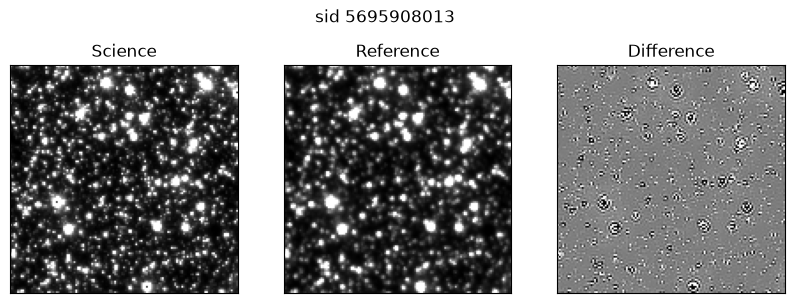

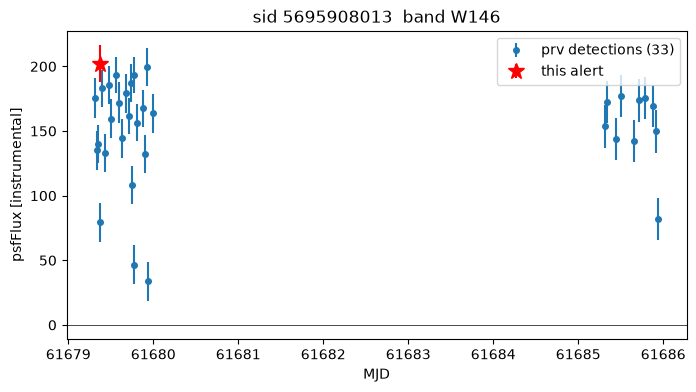

In [8]:
prv, forced = show_alert(alert)

# prv and forced are DataFrames of the history arrays, e.g. prv[["midpointMjd", "psfFlux", "snr"]]

## Whole chips

A chip file holds every alert from one difference image, as an Avro **container** file. The schema is in the file header, so `fastavro.reader` decodes it with nothing else, one record at a time. The next cell is the whole of it; `list()` pulls the chip into memory, or iterate the reader to stream through it.

After that come helpers that flatten a file into a table and summarize it. Their readers only add a sniff of the file's first bytes so one call takes either format:

| function | in | out |
|---|---|---|
| `read_alerts(path, schema=None)` | container or schemaless `.avro` | iterator of alert dicts |
| `read_alert(path, schema=None)` | same | the first (or only) alert, as one dict |
| `alert_table(path, schema=None)` | same | one `DataFrame` row per alert: the `diaSource` fields the summary needs plus history lengths |
| `summarize_alerts(df)` | that frame | dict of counts, brightest/dimmest, mean history lengths |
| `print_summary(s)`, `plot_psfflux(df)` | dict / frame | printed summary, flux histogram |

Notes on what the numbers mean:

- **real** = `reliability >= reliabilityThreshold`. Both are null for the example files until real/bogus scores are backfilled, so the real counts are 0 for now and `scored` says how many detections carry a score.
- **brightest / dimmest** rank by `|psfFlux|`, so a strongly negative detection can be brightest; the line says `pos` or `neg`.
- **diffimglimmag** is a stub and null today.
- The frame `df` is handy on its own for ad hoc questions (sort by `snr`, filter `isNegative`, ...).


In [9]:
# Simple version: the container file carries its own schema, so no load_schema() needed.
# fastavro.reader yields one alert dict at a time, the same shape as the single alert above.
with open(chip_filename, "rb") as f:
    reader = fastavro.reader(f)
    print(f"Schema in file header: {reader.writer_schema['name']}")
    chip_alerts = list(reader)          # whole chip in memory: ~200 KB per alert

print(f"Alerts on chip: {len(chip_alerts)}")
first, last = chip_alerts[0], chip_alerts[-1]
print(f"First alert ID: {first['diaSourceId']}, last alert ID: {last['diaSourceId']}")
print(f"First alert PSF flux: {first['diaSource']['psfFlux']:.4g}, "
      f"previous detections: {len(first['prvDiaSources'] or [])}")

# e.g. the alert with the highest S/N on the chip, straight into show_alert:
# show_alert(max(chip_alerts, key=lambda a: a["diaSource"]["snr"] or 0))

Schema in file header: rapid.v00_07.alert
Alerts on chip: 2189
First alert ID: 5695898488, last alert ID: 5695926762
First alert PSF flux: 377.9, previous detections: 9


In [10]:
def read_alerts(path, schema=None):
    """Yield alert dicts from a file: an Avro container (many alerts, self-describing)
    or one schemaless alert as written from produce_alert() bytes, which needs `schema`."""
    with open(path, "rb") as f:
        # Every Avro object-container file starts with the magic bytes "Obj\x01".
        # Anything else is taken to be one schemaless alert.
        if f.read(4) == b"Obj\x01":
            f.seek(0)
            yield from fastavro.reader(f)   # schema comes from the file header
            return
        if schema is None:
            raise ValueError(
                f"{path} is not an Avro container file, so it is read as one schemaless "
                "alert and needs the schema it was written with: pass "
                "schema=load_schema() (or load_schema(version=...) "
                "for an older alert)")
        f.seek(0)
        yield fastavro.schemaless_reader(f, schema)


def read_alert(path, schema=None):
    """The first (or only) alert in a file, as one dict."""
    return next(read_alerts(path, schema))


def alert_table(path, schema=None):
    """One row per alert: the diaSource fields the summary needs plus history lengths."""
    # Only the triggering diaSource is flattened; prv* arrays are reduced to their length.
    keys = ("diaSourceId", "expId", "detector", "field", "band", "pid", "midpointMjd",
            "isNegative", "psfFlux", "snr", "ra", "dec", "reliability",
            "reliabilityThreshold", "diffimglimmag")
    rows = []
    for a in read_alerts(path, schema):
        row = {k: a["diaSource"].get(k) for k in keys}
        row["n_prv"] = len(a.get("prvDiaSources") or [])          # arrays are nullable
        row["n_forced"] = len(a.get("prvDiaForcedSources") or [])
        row["schemaVersion"] = a.get("schemaVersion")
        row["pipelineVersion"] = a.get("pipelineVersion")
        rows.append(row)
    return pd.DataFrame(rows)


def summarize_alerts(df):
    """Summary dict from an alert_table() frame."""
    # Comparing two nullable columns gives False wherever either side is null,
    # which is the rule we want: not real unless scored and above threshold.
    real = df["reliability"] >= df["reliabilityThreshold"]
    neg = df["isNegative"].astype(bool)
    pick = lambda idx: df.loc[idx, ["diaSourceId", "psfFlux", "snr", "ra", "dec", "isNegative"]].to_dict()
    absflux = df["psfFlux"].abs()                   # rank by magnitude, either sign
    limmag = df["diffimglimmag"].dropna().unique()  # should be one value per chip
    first = df.iloc[0]                              # chip identity, same on every row
    return {
        "chip": first[["expId", "detector", "field", "band", "pid", "midpointMjd",
                       "schemaVersion", "pipelineVersion"]].to_dict(),
        "n_alerts": len(df),
        "n_positive": int((~neg).sum()),      "n_positive_real": int((real & ~neg).sum()),
        "n_negative": int(neg.sum()),         "n_negative_real": int((real & neg).sum()),
        "n_scored": int(df["reliability"].notna().sum()),
        # one value -> that value; several -> sorted list (something is off); none -> None
        "diffimglimmag": limmag[0] if len(limmag) == 1 else (sorted(limmag) or None),
        "brightest": pick(absflux.idxmax()) if absflux.notna().any() else None,
        "dimmest": pick(absflux.idxmin()) if absflux.notna().any() else None,
        "mean_prv_sources": df["n_prv"].mean(),       "frac_with_prv": (df["n_prv"] > 0).mean(),
        "mean_forced_sources": df["n_forced"].mean(), "frac_with_forced": (df["n_forced"] > 0).mean(),
    }


def print_summary(s):
    c = s["chip"]
    print(f"chip: expId={c['expId']} detector={c['detector']} field={c['field']} "
          f"band={c['band']} pid={c['pid']} mjd={c['midpointMjd']}")
    print(f"schema {c['schemaVersion']}  pipeline {c['pipelineVersion']}")
    print(f"alerts: {s['n_alerts']}  scored: {s['n_scored']}")
    print(f"  positive: {s['n_positive']:6d}  real: {s['n_positive_real']}")
    print(f"  negative: {s['n_negative']:6d}  real: {s['n_negative_real']}")
    print(f"diffimglimmag: {s['diffimglimmag']}")
    for label in ("brightest", "dimmest"):
        if e := s[label]:   # None when no row had a finite psfFlux
            print(f"{label:9s} by |psfFlux|: sid={e['diaSourceId']} psfFlux={e['psfFlux']:.4g} "
                  f"snr={e['snr']} ra={e['ra']:.6f} dec={e['dec']:.6f} "
                  f"{'neg' if e['isNegative'] else 'pos'}")
    print(f"mean prvDiaSources: {s['mean_prv_sources']:.2f} ({s['frac_with_prv']:.1%} have any)")
    print(f"mean prvDiaForcedSources: {s['mean_forced_sources']:.2f} ({s['frac_with_forced']:.1%} have any)")


def plot_psfflux(df, bins=50):
    """Histogram of log10 |psfFlux|, positive and negative detections on shared bins."""
    # Fluxes span orders of magnitude, so a linear axis piles everything into one bin.
    # Zero flux has no log; drop it rather than let -inf break the bin edges.
    logflux = np.log10(df["psfFlux"].abs().replace(0, np.nan)).dropna()
    neg = df.loc[logflux.index, "isNegative"].astype(bool)
    lo, hi = logflux.min(), logflux.max()
    if lo == hi:                      # one alert, or all equal: give the bins some width
        lo, hi = lo - 0.5, hi + 0.5
    edges = np.linspace(lo, hi, bins + 1)   # shared bins for both signs
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(logflux[~neg], bins=edges, alpha=0.6, label=f"positive ({(~neg).sum()})")
    ax.hist(logflux[neg], bins=edges, alpha=0.6, label=f"negative ({neg.sum()})")
    ax.set_xlabel("log10 |psfFlux|  [instrumental; nJy calibration pending]")
    ax.set_ylabel("detections")
    ax.set_title(f"pid {df['pid'].iloc[0]}  expId {df['expId'].iloc[0]} sca {df['detector'].iloc[0]}")
    ax.legend()
    plt.show()


### Summarize a file

`alert_table` takes the chip file. A schemaless single alert works too if you pass `schema=load_schema()`, though a one-row summary is not very informative.

To summarize many chip files at once: `pd.DataFrame([summarize_alerts(alert_table(p)) for p in paths])`.

To look at one alert from the chip with `show_alert`, pick it out of the reader, e.g. the brightest one from the summary:

```python
alert = next(a for a in read_alerts(chip_filename) if a["diaSourceId"] == s["brightest"]["diaSourceId"])
show_alert(alert)
```


In [11]:
df = alert_table(chip_filename)
s = summarize_alerts(df)
print_summary(s)

chip: expId=80896 detector=7 field=4637678 band=W146 pid=344197 mjd=61679.368946759256
schema 00.07  pipeline None
alerts: 2189  scored: 0
  positive:   1518  real: 0
  negative:    671  real: 0
diffimglimmag: None
brightest by |psfFlux|: sid=5695905893 psfFlux=5.63e+04 snr=3495.34814453125 ra=268.278813 dec=-28.255078 pos
dimmest   by |psfFlux|: sid=5695914020 psfFlux=162.8 snr=12.680729866027832 ra=268.304045 dec=-28.325539 neg
mean prvDiaSources: 20.33 (100.0% have any)
mean prvDiaForcedSources: 13.95 (99.7% have any)


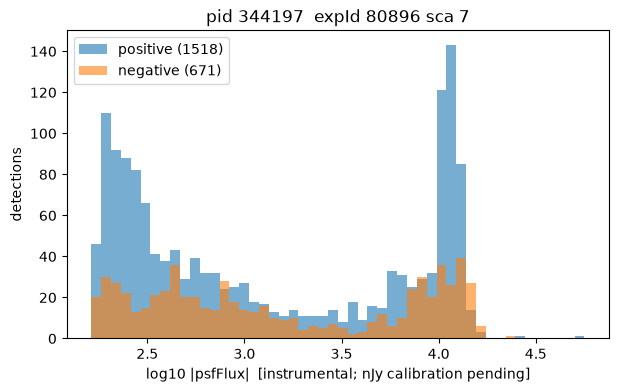

In [12]:
plot_psfflux(df)